# D-FINE: FDR e GO-LSD no mesmo modelo

Este notebook usa um checkpoint **D-FINE-Nano treinado em COCO** para mostrar os dois mecanismos centrais do artigo e como eles se relacionam. Primeiro, acompanhamos uma query pelas camadas e vemos o **Fine-grained Distribution Refinement (FDR)** nas caixas e distribuições. Depois, usamos essas mesmas distribuições para ilustrar a comparação entre camadas que motiva o **Global Optimal Localization Self-Distillation (GO-LSD)**. A ablação publicada mostra o ganho de cada contribuição em sequência.

A primeira execução baixa modelo e imagem e requer internet. CPU funciona, mas pode demorar. Fonte: [artigo](https://arxiv.org/abs/2410.13842), [código oficial](https://github.com/Peterande/D-FINE), [implementação Transformers](https://huggingface.co/docs/transformers/model_doc/d_fine).


## 1. Dependências

Execute a célula seguinte se estiver em Jupyter ou Colab. Reinicie o kernel se a instalação atualizar pacotes já importados.


In [8]:
%pip install -q "transformers==5.14.1" torch pillow matplotlib requests


Note: you may need to restart the kernel to use updated packages.


## 2. Modelo e imagem

A imagem pertence ao COCO val2017. O checkpoint Nano é público; os números de AP e latência do artigo abaixo vêm da variante **L**, com outro tamanho e outro protocolo. O processador prepara a imagem para o modelo; as caixas são depois convertidas para os pixels da imagem original.


In [9]:
from io import BytesIO

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import requests
import torch
from PIL import Image
from transformers import AutoImageProcessor, AutoModelForObjectDetection

MODEL_ID = "ustc-community/dfine-nano-coco"
IMAGE_URL = "https://huggingface.co/datasets/hf-internal-testing/fixtures-coco/resolve/main/val2017/000000039769.jpg"
THRESHOLD = 0.5

response = requests.get(IMAGE_URL, timeout=30)
response.raise_for_status()
image = Image.open(BytesIO(response.content)).convert("RGB")

processor = AutoImageProcessor.from_pretrained(MODEL_ID)
model = AutoModelForObjectDetection.from_pretrained(MODEL_ID)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device).eval()
print(f"Dispositivo: {device}; imagem: {image.width} × {image.height}")


Loading weights: 100%|██████████| 644/644 [00:00<00:00, 4512.44it/s]


Dispositivo: cuda; imagem: 640 × 480


## 3. Inferência e pós processamento

O Transformers 5.14.1 devolve só a camada final em modo de avaliação. Para observar FDR, habilitamos temporariamente a **coleta das saídas intermediárias** no decodificador, mantendo seus submódulos em avaliação. O estado original é restaurado mesmo se a inferência falhar. Isso não ativa treinamento nem altera pesos.


In [10]:
inputs = processor(images=image, return_tensors="pt").to(device)
decoder = model.model.decoder
assert not decoder.training and all(not child.training for child in decoder.children())
decoder.training = True  # Transformers 5.14.1: retém saídas de todas as camadas
try:
    with torch.inference_mode():
        outputs = model(**inputs)
finally:
    decoder.training = False

detections = processor.post_process_object_detection(
    outputs,
    target_sizes=[(image.height, image.width)],
    threshold=THRESHOLD,
)[0]

for score, label_id, box in zip(
    detections["scores"], detections["labels"], detections["boxes"]
):
    label = model.config.id2label[int(label_id)]
    print(f"{label:15s} {float(score):.3f}  {[round(float(v), 1) for v in box]}")
print(f"Detecções acima de {THRESHOLD}: {len(detections['scores'])}")


cat             0.959  [12.2, 54.9, 316.1, 470.6]
cat             0.933  [340.2, 25.6, 639.7, 371.7]
remote          0.922  [40.2, 72.8, 175.9, 118.1]
sofa            0.837  [1.9, 1.8, 639.7, 474.7]
remote          0.804  [334.2, 77.1, 371.6, 188.1]
Detecções acima de 0.5: 5


## 4. Detecções finais

Cada retângulo é uma previsão filtrada por confiança. Essa inspeção qualitativa não mede AP: o AP exige todas as imagens e anotações de validação, com o protocolo COCO.


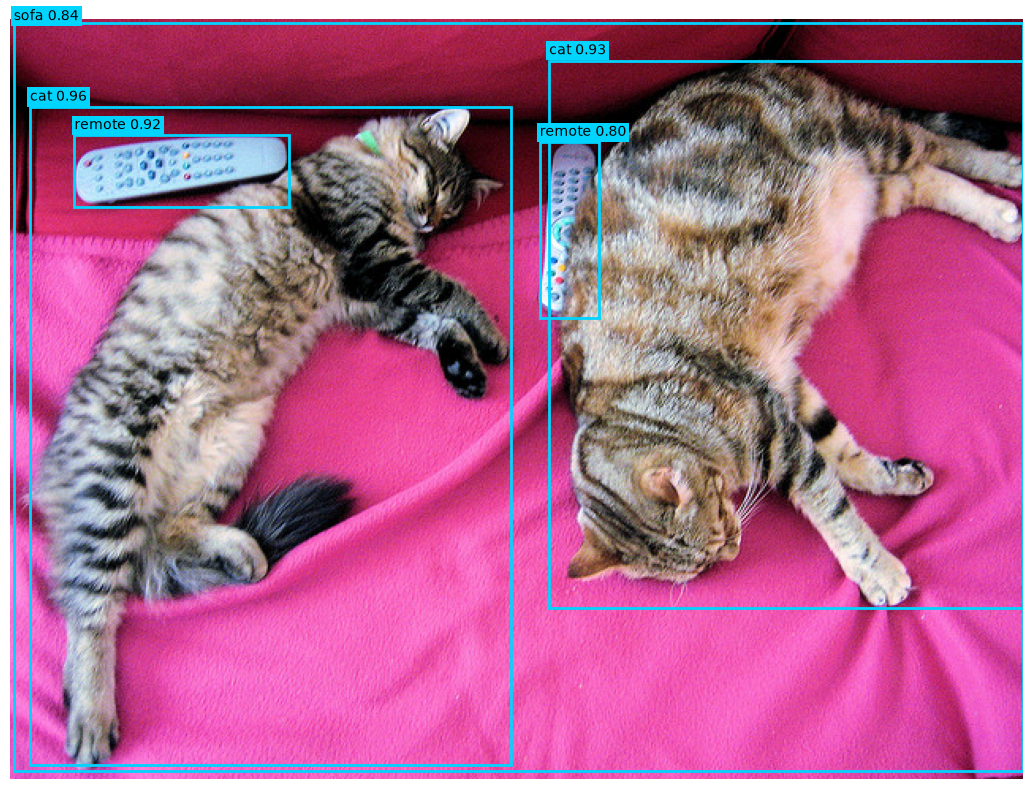

In [11]:
fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(image)
for score, label_id, box in zip(
    detections["scores"], detections["labels"], detections["boxes"]
):
    x1, y1, x2, y2 = map(float, box)
    ax.add_patch(patches.Rectangle(
        (x1, y1), x2 - x1, y2 - y1,
        fill=False, edgecolor="#00d4ff", linewidth=2,
    ))
    ax.text(x1, max(y1 - 4, 0),
            f"{model.config.id2label[int(label_id)]} {float(score):.2f}",
            color="black", fontsize=10,
            bbox={"facecolor": "#00d4ff", "edgecolor": "none", "pad": 2})
ax.axis("off")
plt.tight_layout()
plt.show()


## 5. FDR: a mesma query ao longo do decodificador

Selecionamos a query de maior confiança **na última camada** e mantemos seu índice nas demais. Assim, as caixas mostram o refinamento da mesma query, não as melhores caixas de queries diferentes em cada estágio. A caixa inicial é produzida antes da correção distribuída; as caixas abaixo são as saídas após FDR em cada camada. Um exemplo isolado não prova melhora de AP e uma query pode piorar em alguma camada.

Query 2: cat, confiança final 0.959


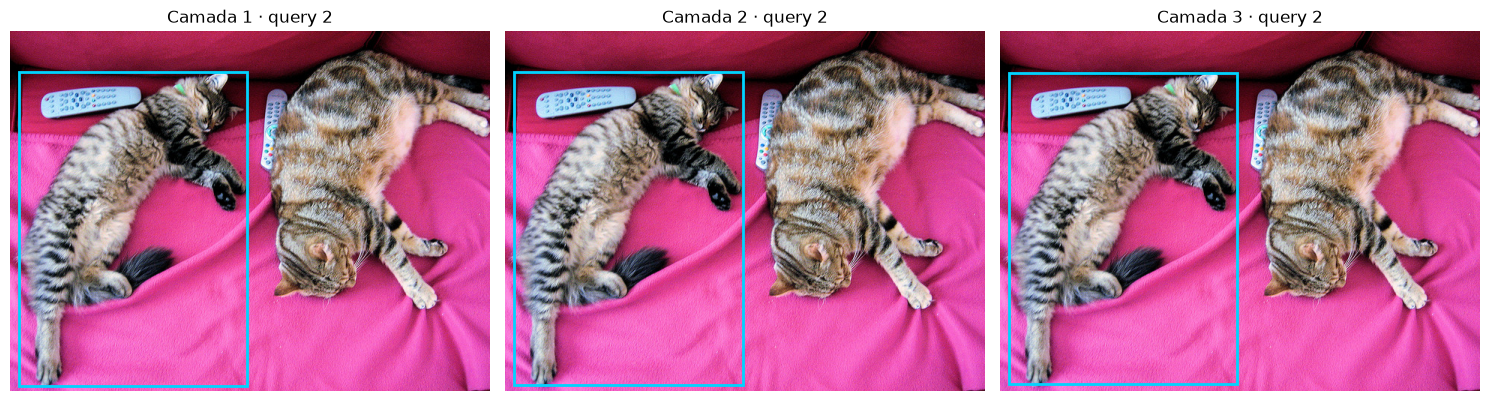

In [12]:
from transformers.image_transforms import center_to_corners_format

layer_boxes = outputs.intermediate_reference_points[0, 1:].detach()
assert layer_boxes.shape[0] == model.config.decoder_layers
assert torch.allclose(layer_boxes[-1], outputs.pred_boxes[0], atol=1e-5)

final_confidence, final_labels = outputs.logits[0].sigmoid().max(dim=-1)
query_index = int(final_confidence.argmax())
label_name = model.config.id2label[int(final_labels[query_index])]
print(f"Query {query_index}: {label_name}, confiança final {float(final_confidence[query_index]):.3f}")

pixel_boxes = center_to_corners_format(layer_boxes[:, query_index]).cpu()
pixel_boxes *= torch.tensor([image.width, image.height, image.width, image.height])
fig, axes = plt.subplots(1, len(pixel_boxes), figsize=(5 * len(pixel_boxes), 4), squeeze=False)
for layer, (ax, box) in enumerate(zip(axes[0], pixel_boxes), start=1):
    x1, y1, x2, y2 = box.tolist()
    ax.imshow(image)
    ax.add_patch(patches.Rectangle(
        (x1, y1), x2 - x1, y2 - y1, fill=False,
        edgecolor="#00d4ff", linewidth=2,
    ))
    ax.set_title(f"Camada {layer} · query {query_index}")
    ax.axis("off")
plt.tight_layout()
plt.show()

### Distribuições das quatro bordas

Cada camada acumula logits de correção para esquerda, topo, direita e base. O softmax transforma esses logits em probabilidades sobre bins; a posição horizontal mostra o valor **não uniforme** w(n) usado pelo modelo. A esperança dessa distribuição corrige a borda em relação à caixa inicial, com escala dada pela largura ou altura inicial. As curvas representam uma estrutura interna de regressão, **não** uma calibração de incerteza.

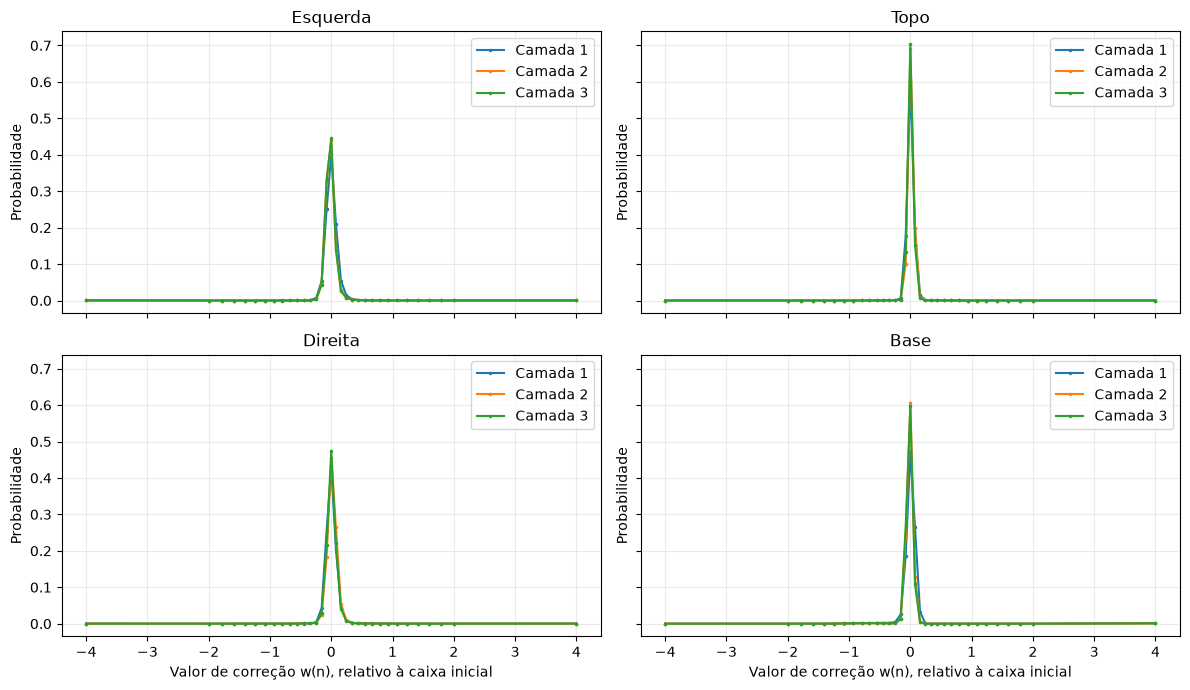

In [13]:
from transformers.models.d_fine.modeling_d_fine import weighting_function

corner_logits = outputs.intermediate_predicted_corners[0]
assert corner_logits.shape[0] == len(layer_boxes)
corner_probs = corner_logits[:, query_index].reshape(
    len(layer_boxes), 4, model.config.max_num_bins + 1
).float().softmax(dim=-1).cpu()
bin_values = weighting_function(
    model.config.max_num_bins, decoder.up.detach(), decoder.reg_scale.detach()
).detach().cpu()

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
for edge, ax in enumerate(axes.flat):
    for layer, probabilities in enumerate(corner_probs[:, edge], start=1):
        ax.plot(bin_values, probabilities, marker=".", markersize=3, label=f"Camada {layer}")
    ax.set_title(("Esquerda", "Topo", "Direita", "Base")[edge])
    ax.set_ylabel("Probabilidade")
    ax.grid(alpha=0.25)
    ax.legend()
for ax in axes[-1]:
    ax.set_xlabel("Valor de correção w(n), relativo à caixa inicial")
plt.tight_layout()
plt.show()

## 6. GO-LSD: a última camada ensina as anteriores

| Pergunta | FDR | GO-LSD |
| --- | --- | --- |
| O que faz? | Refina cada borda com uma distribuição de correções em camadas sucessivas. | Usa as distribuições da camada final como referência para as camadas anteriores. |
| Quando atua? | No treinamento **e** na inferência: produz as caixas. | Só no treinamento: acrescenta supervisão entre camadas. |
| Relação entre eles | Produz as distribuições que serão comparadas. | No D-FINE, **usa as distribuições do FDR**; não é um detector alternativo. |
| Saída visível neste notebook | Caixas e curvas de probabilidade por borda. | Um diagnóstico de divergência entre camadas; a perda completa não pode ser medida aqui. |

Para tornar a relação concreta, comparamos a distribuição de cada borda nas camadas iniciais com a da última camada da **mesma query**. Usamos KL(última camada ∥ camada anterior) com temperatura **T = 5**, como na parte distributiva da destilação. Valores menores indicam distribuições mais parecidas. A última camada, usada como referência, teria divergência zero consigo mesma e por isso não aparece no mapa.

**Este mapa não é a perda GO-LSD do artigo.** O treinamento também usa anotações COCO, a união dos emparelhamentos húngaros entre camadas e pesos ligados a IoU ou confiança. Com um único checkpoint já treinado e sem anotações, não há atualização de pesos nem como isolar o efeito de GO-LSD.

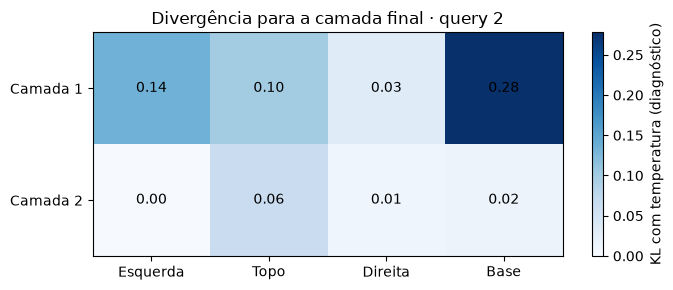

In [14]:
import torch.nn.functional as F

temperature = 5.0
selected_logits = corner_logits[:, query_index].reshape(
    len(layer_boxes), 4, model.config.max_num_bins + 1
).float()
teacher_distribution = F.softmax(selected_logits[-1].detach() / temperature, dim=-1)
student_log_distribution = F.log_softmax(selected_logits[:-1] / temperature, dim=-1)
diagnostic_kl = (
    F.kl_div(
        student_log_distribution,
        teacher_distribution.unsqueeze(0).expand_as(student_log_distribution),
        reduction="none",
    ).sum(dim=-1) * temperature**2
).detach().cpu()

fig, ax = plt.subplots(figsize=(7, 3))
heatmap = ax.imshow(diagnostic_kl.numpy(), cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(4), ["Esquerda", "Topo", "Direita", "Base"])
ax.set_yticks(range(len(diagnostic_kl)), [f"Camada {i}" for i in range(1, len(diagnostic_kl) + 1)])
ax.set_title(f"Divergência para a camada final · query {query_index}")
for row in range(len(diagnostic_kl)):
    for edge in range(4):
        ax.text(edge, row, f"{float(diagnostic_kl[row, edge]):.2f}", ha="center", va="center")
fig.colorbar(heatmap, ax=ax, label="KL com temperatura (diagnóstico)")
plt.tight_layout()
plt.show()

## 7. O que as ablações mostram?

A [Tabela 3 do artigo](https://arxiv.org/html/2410.13842v1) acompanha a variante **L** desde RT-DETR-HGNetv2-L até D-FINE-L. Os autores mediram AP no **COCO val2017** e latência em **TensorRT FP16, lote 1, NVIDIA T4**. Cada linha incorpora as alterações anteriores; os números abaixo são **publicados pelos autores**, não produzidos pelo notebook.

| Etapa acumulada | AP | Parâmetros | Latência T4 | GFLOPs |
| --- | ---: | ---: | ---: | ---: |
| RT-DETR-HGNetv2-L | 53,0 | 32 M | 9,25 ms | 110 |
| Remove projeções do decodificador | 52,4 | 32 M | 8,02 ms | 97 |
| + Target Gating | 52,8 | 33 M | 8,15 ms | 98 |
| + CSP → GELAN | 53,5 | 46 M | 10,69 ms | 167 |
| + Reduz pela metade a dimensão do GELAN | 52,8 | 31 M | 8,01 ms | 91 |
| + Amostragem desigual entre escalas | 52,9 | 31 M | 7,90 ms | 91 |
| + Estratégia de treinamento RT-DETRv2 | 53,0 | 31 M | 7,90 ms | 91 |
| + FDR | 53,5 | 31 M | 8,07 ms | 91 |
| + GO-LSD | **54,0** | 31 M | 8,07 ms | 91 |

Após os ajustes de eficiência, **FDR acrescenta 0,5 ponto de AP**; **GO-LSD acrescenta mais 0,5** nessa sequência. A linha +GO-LSD já **inclui FDR**: a tabela compara FDR sozinho com FDR + GO-LSD, não apresenta GO-LSD isolado. A redução de GFLOPs e latência frente ao baseline vem principalmente dos ajustes arquiteturais. O gráfico destaca quatro marcos dessa tabela.

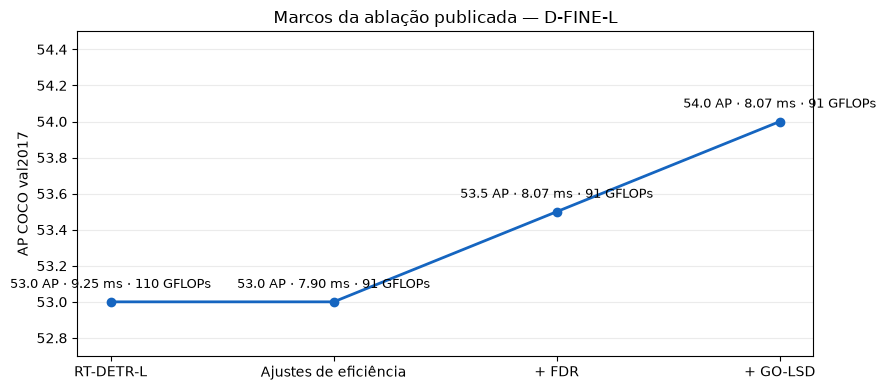

In [15]:
stages = ["RT-DETR-L", "Ajustes de eficiência", "+ FDR", "+ GO-LSD"]
ap = [53.0, 53.0, 53.5, 54.0]
latency_ms = [9.25, 7.90, 8.07, 8.07]
gflops = [110, 91, 91, 91]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(len(stages)), ap, marker="o", linewidth=2, color="#1565c0")
for index, (score, latency, compute) in enumerate(zip(ap, latency_ms, gflops)):
    ax.annotate(
        f"{score:.1f} AP · {latency:.2f} ms · {compute} GFLOPs",
        (index, score), xytext=(0, 10), textcoords="offset points",
        ha="center", fontsize=9,
    )
ax.set_xticks(range(len(stages)), stages)
ax.set_ylim(52.7, 54.5)
ax.set_ylabel("AP COCO val2017")
ax.set_title("Marcos da ablação publicada — D-FINE-L")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 8. O que foi reproduzido?

| O que este notebook mostra | O que ele não reproduz |
| --- | --- |
| Detecções e caixas do D-FINE-Nano em uma imagem | AP em todo o COCO val2017 |
| Refinamento real de uma query nas camadas | Treinamento com FGL e GO-LSD |
| Distribuições FDR e um diagnóstico KL entre camadas | Perda GO-LSD completa e ganho causal do método |
| Ablação publicada para D-FINE-L | Latência T4 com TensorRT FP16 |

O gráfico de KL mostra a **relação matemática** entre as distribuições que GO-LSD usa. A evidência de ganho vem da ablação publicada, não deste gráfico. Não compare a duração de uma célula em PyTorch/CPU com a latência publicada: hardware, backend, precisão, aquecimento e escopo da medição são diferentes.
